# 21. MLOps with covariates: real electricity demand

**Goal and requirements.** An operations project on real data: forecast, every day, the next day's electricity demand in Victoria (Australia) with temperature, holidays and weekends. The flow is the one of notebook 19, now with the covariates kept in the same SQLite database: the weather forecast and the calendar arrive the day before, the observed temperature arrives with the demand. Training, registration, promotion, daily operation through 2014, monitoring and gated retraining. `stats` and `plot` extras; downloads the data on the first run.

In [1]:
import shutil
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment, ExperimentStore, save_model
from autohybts.datasets import load_exog_dataset

warnings.filterwarnings("ignore")
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc3


## 1. Data and protocol

`vic_elec_daily` aggregates the half-hourly demand of 2012 to 2014 into GWh per day, with the maximum temperature, the holiday and the weekend. Demand rises in cold and in heat, so temperature also enters squared.

The dataset has no weather forecasts. Here the forecast is **simulated**: the observed temperature plus a normal error with a 2 °C standard deviation, a typical value for a next-day forecast. With that, each column has an honest role:

- `feriado`, `fim_de_semana`, `temperatura_prevista` (and its square): `future`, known the day before;
- `temperatura_max` (and its square): `past`, observed with the demand and used with a 1-day lag.

The model goes into production on 1 January 2014 and forecasts one day at a time (protocol B). The gate uses the 60 sealed days of each training; monitoring uses the 28-day rolling MAE against 1.5 times the reference; retraining happens on an alert (at most one every 60 days) or every 120 days.

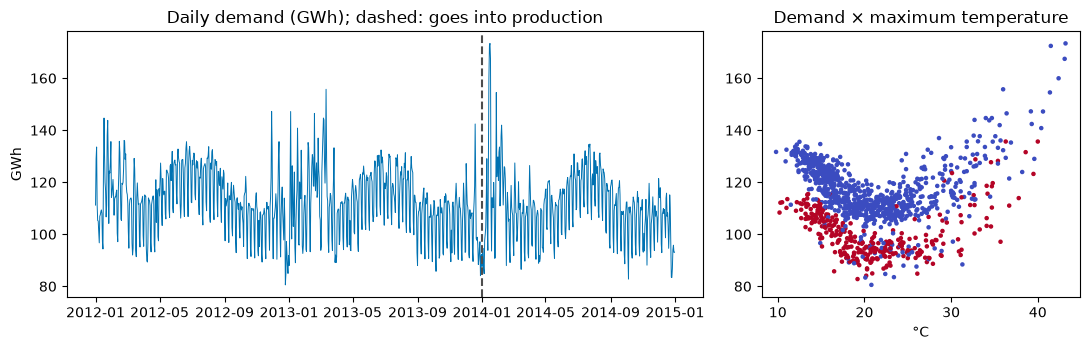

In [2]:
demand, X = load_exog_dataset("vic_elec_daily")
rng = np.random.default_rng(42)
X["temperatura_prevista"] = X["temperatura_max"] + rng.normal(0, 2.0, len(X))
X["temperatura_prevista2"] = X["temperatura_prevista"] ** 2
FUTURE = ["feriado", "fim_de_semana", "temperatura_prevista", "temperatura_prevista2"]
PAST = ["temperatura_max", "temperatura_max2"]
NAME, DEPLOY, GATE, WINDOW, THRESHOLD, SCHEDULE = "demanda_vic", 731, 60, 28, 1.5, 120

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(demand.index, demand.to_numpy(), linewidth=0.7, color="#0072B2")
axes[0].axvline(demand.index[DEPLOY], color="0.3", linestyle="--")
axes[0].set(title="Daily demand (GWh); dashed: goes into production", ylabel="GWh")
axes[1].scatter(X["temperatura_max"], demand, s=5, c=X["fim_de_semana"], cmap="coolwarm")
axes[1].set(title="Demand × maximum temperature", xlabel="°C")
fig.tight_layout()
plt.show()

## 2. Training, registration and promotion

`train` is the pipeline: experiment with the covariates (the selection decides whether they enter), finalization, single read of the sealed test (its MAE becomes the reference), logging of the experiment, artifact and model. The covariates up to deployment go to the database's `covariates` table: the service reads what it needs from there.

In [3]:
folder = Path("artifacts/mlops_energy")
shutil.rmtree(folder, ignore_errors=True)
store = ExperimentStore(folder / "energia.db")
SERIES = "__single__"
SETTINGS = {
    "fh": 1,
    "variant": "B",
    "test_size": GATE,
    "session_id": 42,
    "budget": "small",
    "base_models": ["seasonal_naive", "linear", "knn"],
    "correctors": ["linear"],
    "exog_future": FUTURE,
}


def train(t, label):
    exp = AutoHybridExperiment(**SETTINGS).fit(demand.iloc[:t], X.iloc[:t])
    result = exp.compare_models()
    final = exp.finalize_model(result.best)
    mae = float(exp.evaluate_external(final).metrics["MAE"].iloc[0])
    run_id = store.log(exp, name=label, models=[final], values=True)
    path = save_model(final, folder / "models" / final.model_id[:12])
    store.register_model(final, path, name=NAME, run_id=run_id, reference_mae=mae)
    return final, mae, run_id


store.log_covariates(SERIES, X.iloc[:DEPLOY])
first, reference, _ = train(DEPLOY, "initial-training")
store.promote(first.model_id, reason="first model")
store.query(
    """
    SELECT d.family, d.challenger_label AS challenger, d.accepted AS accepted,
           ROUND(d.median_gain, 3) AS median_gain
    FROM decisions d JOIN runs r USING (run_id) WHERE r.name = 'initial-training'
    """
)

,family,challenger,accepted,median_gain
0,statistical,seasonal_naive(season_length=7),0,-0.871
1,linear,linear(lags=7),0,-0.694
2,residual,"knn(lags=7) + linear [w=7, alpha=0.5, historic...",0,0.290
3,exogenous,"knn(lags=7) + linear [w=7, alpha=1.0, historic...",1,0.510


## 3. Daily operation

The day before, the weather forecast and the calendar arrive: they go to the database and to `predict_next`. The next day, the demand and the observed temperature arrive: they go to the database and to `observe`. The service loads the production model from the registry and updates it, without refitting, with the observations and covariates read from the `covariates` table.

In [4]:
def serve(t):
    """Production model from the registry, updated up to day t with the stored covariates."""
    model = store.load(NAME, trusted=True)
    start = demand.index.get_loc(model.last_observation) + 1
    if start > t:
        return model.stream()
    covariates = store.covariates(SERIES, demand.index[start], demand.index[t])
    return model.update_state(demand.iloc[start : t + 1], X_new=covariates).stream()


stream, events, last_retrain = serve(DEPLOY - 1), [], DEPLOY
for t in range(DEPLOY, len(demand)):
    day = demand.index[t]
    ahead = X.loc[[day], FUTURE]  # known the day before
    store.log_covariates(SERIES, ahead)
    ticket = stream.predict_next(ahead)
    model_id = stream.model.model_id
    store.log_forecasts(
        model_id,
        pd.DataFrame(
            {
                "timestamp": [ticket.timestamp],
                "origin": [ticket.origin],
                "y_pred": [ticket.prediction],
            }
        ),
    )
    observed = X.loc[[day], PAST]  # arrives with the demand
    stream.observe(float(demand.iloc[t]), observed)
    store.log_covariates(SERIES, observed)
    store.log_actuals(SERIES, demand.iloc[t : t + 1])
    alert = bool(store.monitor(model_id, window=WINDOW, threshold=THRESHOLD).alert.iloc[-1])
    if not ((alert and t - last_retrain >= GATE) or t - last_retrain >= SCHEDULE):
        continue
    reason = "alert" if alert else "schedule"
    challenger, challenger_mae, run_id = train(t + 1, f"retraining-{day.date()}")
    live_mae = store.query(
        """
        SELECT AVG(ABS(a.y_true - f.y_pred)) AS mae
        FROM forecasts f JOIN actuals a USING (series_id, timestamp)
        WHERE f.model_id = ? AND f.timestamp IN (SELECT timestamp FROM predictions WHERE run_id = ?)
        """,
        (model_id, run_id),
    ).mae[0]
    promoted = challenger_mae <= live_mae
    if promoted:
        store.promote(
            challenger.model_id, reason=f"{reason}: MAE {challenger_mae:.2f} <= {live_mae:.2f}"
        )
        stream = serve(t)
    events.append(
        {
            "day": day.date(),
            "reason": reason,
            "challenger": challenger.spec.label,
            "challenger_mae": round(challenger_mae, 2),
            "production_mae": round(live_mae, 2),
            "promoted": promoted,
        }
    )
    last_retrain = t
pd.DataFrame(events)

,day,reason,challenger,challenger_mae,production_mae,promoted
0,2014-03-02,alert,linear(lags=7),11.72,7.39,False
1,2014-06-30,schedule,"knn(lags=7) | exog: feriado, fim_de_semana, te...",2.51,2.37,False
2,2014-10-28,schedule,knn(lags=7),2.78,2.47,False


## 4. Monitoring

The stage history and each model's real error over the period it was in production, against its reference.

In [5]:
store.query(
    """
    SELECT r.label, MIN(f.timestamp) AS first_day, MAX(f.timestamp) AS last_day, COUNT(*) AS days,
           ROUND(AVG(ABS(a.y_true - f.y_pred)), 2) AS live_mae,
           ROUND(r.reference_mae, 2) AS reference_mae
    FROM forecasts f
    JOIN actuals a USING (series_id, timestamp)
    JOIN registry r USING (model_id)
    GROUP BY f.model_id ORDER BY first_day
    """
)

,label,first_day,last_day,days,live_mae,reference_mae
0,"knn(lags=7) + linear [w=7, alpha=1.0, historic...",2014-01-01T00:00:00,2014-12-31T00:00:00,365,3.47,3.12


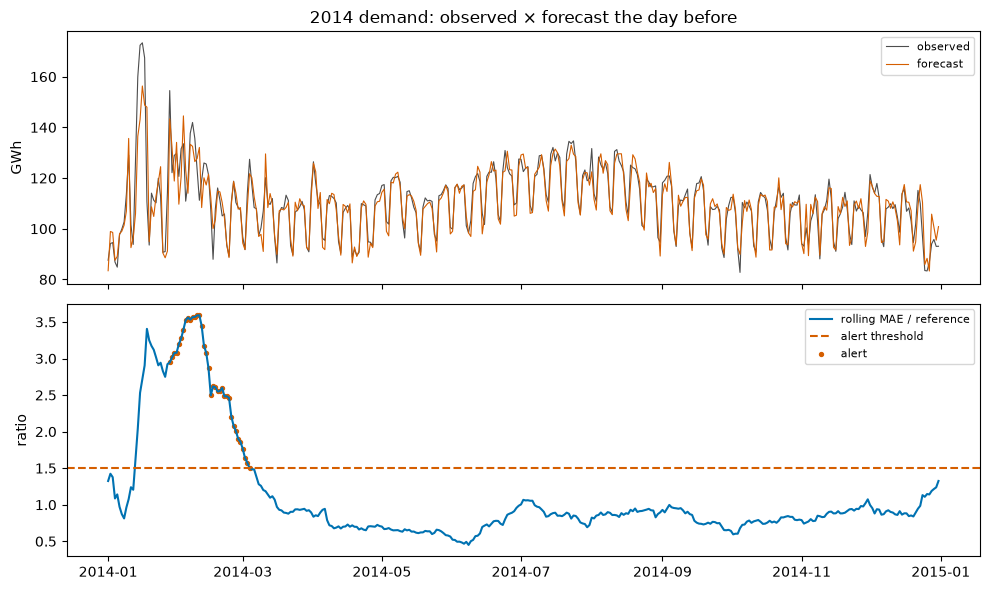

In [6]:
status = pd.concat(
    [
        store.monitor(m, window=WINDOW, threshold=THRESHOLD)
        for m in store.query("SELECT DISTINCT model_id FROM forecasts").model_id
    ]
).sort_values("timestamp")
status["timestamp"] = pd.to_datetime(status.timestamp)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(status.timestamp, status.y_true, color="0.3", linewidth=0.8, label="observed")
axes[0].plot(status.timestamp, status.y_pred, color="#D55E00", linewidth=0.8, label="forecast")
axes[0].set(ylabel="GWh", title="2014 demand: observed × forecast the day before")
axes[0].legend(fontsize=8)
axes[1].plot(status.timestamp, status.ratio, color="#0072B2", label="rolling MAE / reference")
axes[1].axhline(THRESHOLD, color="#D55E00", linestyle="--", label="alert threshold")
alerts = status[status.alert]
axes[1].scatter(alerts.timestamp, alerts.ratio, s=8, color="#D55E00", label="alert")
axes[1].set(ylabel="ratio")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Evaluating the operation

The forecasts used against two references computed in the database itself: persistence (the previous day, `LAG(1)`) and weekly persistence (the same weekday a week earlier, `LAG(7)`). By quarter, to see whether the gain holds across seasons.

In [7]:
quarters = store.query(
    """
    WITH o AS (
        SELECT timestamp, y_true,
               LAG(y_true, 1) OVER (ORDER BY timestamp) AS yesterday,
               LAG(y_true, 7) OVER (ORDER BY timestamp) AS last_week
        FROM actuals
    )
    SELECT 'Q' || ((CAST(strftime('%m', o.timestamp) AS INTEGER) + 2) / 3) AS quarter,
           COUNT(*) AS days,
           ROUND(AVG(ABS(o.y_true - f.y_pred)), 2) AS operation_mae,
           ROUND(AVG(ABS(o.y_true - o.yesterday)), 2) AS persistence_mae,
           ROUND(AVG(ABS(o.y_true - o.last_week)), 2) AS weekly_mae
    FROM forecasts f JOIN o USING (timestamp)
    WHERE o.last_week IS NOT NULL
    GROUP BY quarter ORDER BY quarter
    """
)
quarters

,quarter,days,operation_mae,persistence_mae,weekly_mae
0,Q1,83,6.17,10.92,14.62
1,Q2,91,2.33,6.26,5.19
2,Q3,92,2.48,6.85,4.69
3,Q4,92,3.19,6.80,5.45


In [8]:
store.query(
    """
    SELECT ROUND(AVG(ABS(p.value - o.value)), 2) AS mean_temperature_forecast_error,
           COUNT(*) AS days
    FROM covariates p
    JOIN covariates o ON o.series_id = p.series_id AND o.timestamp = p.timestamp
    WHERE p.column = 'temperatura_prevista' AND o.column = 'temperatura_max'
      AND p.timestamp >= ?
    """,
    (demand.index[DEPLOY].isoformat(),),
)

,mean_temperature_forecast_error,days
0,1.51,365


## 6. Reading

- **Initial training.** With two years of history, the `exogenous` family was accepted with a median gain of 51 % over the univariate champion. The production model is a KNN on 7 lags with a linear corrector, using the weather forecast, the holiday, the weekend and the previous day's temperature. The residual correction without covariates had a 29 % gain but did not pass the acceptance rule.
- **2014 operation.** The same model stayed in production for all 365 days, with a live MAE of 3.47 GWh against the sealed test's 3.12 reference. There were three retrainings: one on an alert, on 2 March, after the heat of the Australian summer, and two on schedule. No challenger passed the gate. The alert's challenger, trained without covariates (the selection refused them in that training), had an MAE of 11.72 on its 60 sealed days, against production's real 7.39 on the same dates.
- **Against the references.** The operation beat both persistence references in every quarter. In the first quarter, the hardest because of heat waves, MAE was 6.17 GWh, against 10.92 for the previous day and 14.62 for the previous week. In the other quarters it stayed between 2.3 and 3.2, less than half of persistence.
- **Auditable inputs.** The `covariates` table keeps what the model received the day before and what was observed afterwards. One query shows the mean error of the weather forecast used: 1.51 °C. Here the forecast is simulated; with a real forecast, log the column and repeat the query.
- **What the database allows.** The service rebuilds the production model from the registry and the stored covariates. Every decision (training, gate, alert) is traceable with SQL.